# Évaluation subjective (MOS) : protocole d'écoute et agrégateur

**Navigation** : [Index](../README.md) | [<< Précédent](04-18-Basic-Pitch-Transcription.ipynb)

**Epic #20568** (pli 4) | Suite de `04-7-TTS-Voice-Benchmark.ipynb` : le protocole et l'agrégateur qui manquent à la grille MOS

## Objectifs

1. Lire la rubrique subjective **depuis son carnet de référence**, sans la recopier
2. Construire une liste d'essais randomisée et une fiche de notation pré-remplie
3. Agréger des notes en MOS avec un intervalle de confiance à 95 % et le rejet des auditeurs aberrants (ITU-R P.808)
4. Mesurer des proxies automatiques (SNR, SI-SDR, distance log-spectrale, STOI) sur un signal de laboratoire dégradé de façon maîtrisée
5. Délimiter ce qu'un proxy classe et ce qu'une oreille note

## 1. Ce qui existe déjà, et ce qui manquait

Le carnet `04-7-TTS-Voice-Benchmark.ipynb` (section 10) pose la **rubrique** : 5 critères, une échelle 1-5, la référence ITU-T P.800, et une grille **vide**, livrée telle quelle — un état valide du carnet, puisque les notes sont celles de l'auditeur.

Ce que la rubrique ne dit pas : dans quel ordre présenter les échantillons, comment détecter un jury qui note à l'envers du groupe, comment lire l'incertitude du résultat.

C'est cet entre-deux que l'organe `scripts/tts_verification/mos_protocol.py` occupe — famille de `verify_transcript.py`, `verify_diarization.py`, `verify_prosody.py`, qui restent le **plancher objectif** mesuré avant l'oreille. Le carnet ci-dessous **l'importe** : aucune ligne de l'organe n'est recopiée ici.


In [1]:
# Branchement de l'organe : on l'importe, on ne le recopie pas.
import sys
from pathlib import Path

import numpy as np
import scipy
import torch
import torchmetrics

REPO_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "scripts" / "tts_verification" / "mos_protocol.py").is_file():
        REPO_ROOT = candidate
        break
assert REPO_ROOT is not None, (
    "organe introuvable : exécuter ce carnet depuis le dépôt "
    "(racine = dossier contenant scripts/tts_verification/mos_protocol.py)"
)
sys.path.insert(0, str(REPO_ROOT / "scripts" / "tts_verification"))

import mos_protocol as mp

print("racine du dépôt :", REPO_ROOT)
print("numpy %s | scipy %s | torch %s | torchmetrics %s"
      % (np.__version__, scipy.__version__, torch.__version__, torchmetrics.__version__))
print("organe importée :", mp.__file__)


racine du dépôt : C:\dev\wt-22062-po2028
numpy 2.2.6 | scipy 1.18.1 | torch 2.14.1+cu126 | torchmetrics 1.9.0
organe importée : C:\dev\wt-22062-po2028\scripts\tts_verification\mos_protocol.py


In [2]:
# La rubrique et les essais sont LUS dans le carnet de référence (04-7) :
# ils ne sont ni réécrits ni dupliqués ici.
rubric = mp.load_rubric(repo_root=REPO_ROOT)
items = mp.load_grid_items(repo_root=REPO_ROOT)

print("source de la rubrique :", Path(rubric.source).name)
print("critères (%d) : %s" % (len(rubric.criteria), ", ".join(rubric.criteria)))
print("échelle : %d - %d" % rubric.scale)
print("référence :", rubric.reference)
print()
print("essais de la séance (%d) :" % len(items))
for item in items:
    print("   - %-22s %s" % (item["id"], item["label"]))


source de la rubrique : 04-7-TTS-Voice-Benchmark.ipynb
critères (5) : naturalite, francais, intelligibilite, expressivite, fidelite
échelle : 1 - 5
référence : P.800

essais de la séance (9) :
   - Kokoro-narration       Kokoro / narration
   - Qwen3-narration        Qwen3 / narration
   - OpenAI-narration       OpenAI / narration
   - Kokoro-dialogue        Kokoro / dialogue
   - Qwen3-dialogue         Qwen3 / dialogue
   - OpenAI-dialogue        OpenAI / dialogue
   - Kokoro-monologue       Kokoro / monologue
   - Qwen3-monologue        Qwen3 / monologue
   - OpenAI-monologue       OpenAI / monologue


### Lecture du résultat

Trois choses sont vérifiées à l'exécution, pas récitées : les **5 critères** viennent du carnet `04-7` (`naturalite`, `francais`, `intelligibilite`, `expressivite`, `fidelite`), l'**échelle 1-5** et la **référence P.800** en sont également issues, et les **9 essais** de la séance sont ceux de la grille du même carnet. Si la rubrique évolue là-bas, ce carnet suit — il ne peut pas diverger d'une recopie.

Noter aussi ce que la lecture ne fait pas : la grille du `04-7` reste **vide**, et elle doit le rester. Un MOS issu de ce carnet serait une note simulée présentée comme une note humaine ; l'agrégateur qui suit est donc exercé sur un jeu **explicitement fictif**.


## 2. Le protocole : ordre de présentation, ancrage, fiche de notation

Un jury qui note toujours les mêmes systèmes dans le même ordre converge vers des notes de **position**, pas de qualité. Le protocole mélange donc l'ordre de présentation (graine fixée : la séance est rejouable, donc auditable) et prévoit des **ancres** — échantillons de référence dont la note est connue, qui servent à détecter une dérive du jury au cours de la session.

La fiche de notation est **pré-remplie** au schéma de la rubrique et **vide** : c'est la seule forme honnête dans un carnet commité — l'instrument est livré, la note reste à l'auditeur.


In [3]:
# Étape 1 : l'ordre de présentation (graine fixée -> séance rejouable).
trial = mp.build_trial_list(items, seed=20261022, anchor_ids=[items[0]["id"]])
for entry in trial:
    print("%2d. %-22s %s" % (entry["presentation_order"], entry["label"],
                              "(ancre)" if entry["is_anchor"] else ""))

# Étape 2 : la fiche de notation, pré-remplie au schéma de la rubrique.
sheet = mp.rating_sheet(trial, rubric)
print()
print("fiche de notation : %d lignes, %d colonnes de note"
      % (len(sheet), len(rubric.criteria)))
print("colonnes :", ", ".join(rubric.criteria))
print("notes pré-remplies :", [sheet[0][c] for c in rubric.criteria])


 1. Kokoro / dialogue      
 2. OpenAI / narration     
 3. Qwen3 / monologue      
 4. OpenAI / monologue     
 5. Kokoro / narration     (ancre)
 6. Qwen3 / narration      
 7. Kokoro / monologue     
 8. Qwen3 / dialogue       
 9. OpenAI / dialogue      

fiche de notation : 9 lignes, 5 colonnes de note
colonnes : naturalite, francais, intelligibilite, expressivite, fidelite
notes pré-remplies : [None, None, None, None, None]


### Lecture du résultat

L'ordre de présentation est **mélangé** et **rejouable** : la graine `20261022` redonne exactement la même séance, ce qui rend la campagne auditable (un jury peut être convoqué à nouveau dans les mêmes conditions) ; une autre graine donnerait un autre ordre, sans changer les essais.

La fiche porte une ligne par essai, dans l'ordre de présentation, avec une colonne vide par critère (`None`). C'est l'état attendu d'une fiche pré-remplie : `aggregate_mos` refusera plus tard toute note manquante plutôt que de la remplacer par une valeur par défaut silencieuse.

L'ancre est signalée dans la liste : c'est l'échantillon dont la note connue doit rester stable au cours de la session. Si elle dérive, c'est le jury qui a dérivé — pas le système qui a changé.


## 3. L'agrégateur : MOS, intervalle de confiance, rejet des auditeurs aberrants

Trois questions distinctes, trois réponses distinctes :

- **combien** : le MOS, moyenne des MOS par essai (chaque MOS d'essai = moyenne des auditeurs sur cet essai) ;
- **à quel degré de certitude** : l'intervalle de confiance à 95 % du MOS (loi de Student, `n-1` degrés de liberté sur les MOS d'essais) — c'est l'incertitude sur le score du système, pas la stabilité d'un auditeur ;
- **qui peut-on écarter** : la règle d'ITU-R P.808 — un auditeur est écarté si sa moyenne s'écarte d'au moins 2 sigma de la moyenne des auditeurs **et** si sa moyenne est inférieure à 0,85 x MOS.

**Les notes utilisées ci-dessous sont fictives** : elles sont simulées pour prouver que la chaîne (protocole -> saisie -> agrégation) fonctionne de bout en bout. Aucune note de ce carnet n'est une note humaine, et aucune ne doit être lue comme telle.


In [4]:
# Campagne FICTIVE : 6 auditeurs « raisonnables » + 1 aberrant.
# Le panel est volontairement large : sur un jury trop petit, l'écart-type
# des moyennes d'auditeurs est gonflé par l'aberrant lui-même et la règle
# P.808 ne peut plus se déclencher.
rng = np.random.default_rng(20261022)
judges = {"j1": 0.00, "j2": 0.20, "j3": -0.15, "j4": 0.12, "j5": -0.10, "j6": 0.05}
item_bias = {item["id"]: float(rng.normal(0.0, 0.6)) for item in items}

records = []
for judge_id, judge_bias in judges.items():
    for item in items:
        base = 3.4 + item_bias[item["id"]] + judge_bias
        records.append({
            "item_id": item["id"],
            "judge_id": judge_id,
            "scores": {c: float(np.clip(base + 0.08 * k, 1, 5))
                       for k, c in enumerate(rubric.criteria)},
        })

# Un septième auditeur qui note à l'envers du groupe.
for item in items:
    base = 1.6 + item_bias[item["id"]]
    records.append({
        "item_id": item["id"],
        "judge_id": "j7",
        "scores": {c: float(np.clip(base, 1, 5)) for c in rubric.criteria},
    })

report = mp.aggregate_mos(records, rubric=rubric)
print(mp.format_report(report))


MOS global : 3.575
IC 95 % : [3.279, 3.870] (+/- 0.295)
Essais : 9 | Auditeurs retenus : 6
Rejet P.808 : j7

MOS par essai :
  - Kokoro-narration : 3.446
  - Qwen3-narration : 3.561
  - OpenAI-narration : 3.252
  - Kokoro-dialogue : 3.465
  - Qwen3-dialogue : 3.761
  - OpenAI-dialogue : 3.805
  - Kokoro-monologue : 4.233
  - Qwen3-monologue : 2.876
  - OpenAI-monologue : 3.774

Moyenne par auditeur :
  - j1 : 3.555
  - j2 : 3.755
  - j3 : 3.405
  - j4 : 3.675
  - j5 : 3.455
  - j6 : 3.605


### Lecture du résultat

Le rapport dit trois choses qu'un MOS seul ne dit pas :

- **le MOS** sort à 3,575, avec un intervalle de confiance à 95 % de [3,279 ; 3,870] : la largeur de cet intervalle est l'incertitude sur le score du système ;
- **l'auditeur aberrant est nommé** (`j7`) : la règle P.808 l'écarte parce que sa moyenne est à la fois trop éloignée du groupe et inférieure à 0,85 x MOS. Le rejet est **visible** dans le rapport — un rejet muet serait invérifiable ;
- **le panel retenu** est explicite à côté du nombre d'essais : 9 essais, 6 auditeurs retenus sur 7.

Et la réserve de fond : ces notes sont **simulées**. Ce que cette section prouve, c'est que la chaîne fonctionne ; elle ne prouve rien sur la qualité d'un moteur de TTS.


## 4. Les proxies automatiques : ce qu'ils mesurent, et ce qu'ils ne disent pas

Avant l'oreille, la chaîne `scripts/tts_verification/` mesure l'objectif (transcription, diarisation, prosodie). Un second niveau de contrôles automatiques existe : les **métriques de dégradation**, qui comparent un signal à sa référence.

Le signal de référence est **synthétique** (modèle source-filtre : excitation glottale à 120 Hz modulée en jitter, filtre de formants à deux voyelles) : aucune voix de production n'est impliquée, aucune donnée externe n'est nécessaire. Les dégradations sont **maîtrisées** : bruit additif à trois SNR, passe-bas à deux coupures, écrêtage.

Quatre mesures : SNR global, SI-SDR (`torchmetrics`), distance log-spectrale (LSD), STOI (`torchmetrics`, qui demande `pystoi`).


In [5]:
# Référence de laboratoire : modèle source-filtre (excitation glottale ->
# filtre de formants). Aucune voix de production, aucune donnée externe.
from scipy import signal
from torchmetrics.functional.audio import (
    scale_invariant_signal_distortion_ratio as si_sdr_metric,
)
from torchmetrics.functional.audio.stoi import (
    short_time_objective_intelligibility as stoi_metric,
)

FS = 16_000
DURATION = 3.0
rng = np.random.default_rng(20261022)


def glottal_excitation(duration=DURATION, fs=FS, f0=120.0, jitter=0.02):
    """Excitation glottale : train d'impulsions à F0, modulé en jitter."""
    n = int(duration * fs)
    instants = []
    t = 0.0
    while t < duration:
        instants.append(t)
        t += (1.0 / f0) * (1.0 + rng.normal(0.0, jitter))
    index = (np.asarray(instants) * fs).astype(int)
    index = index[index < n]
    excitation = np.zeros(n)
    excitation[index] = 1.0
    return excitation


def resonator(x, frequency, bandwidth, fs=FS):
    """Résonateur à deux pôles : un formant."""
    r = np.exp(-np.pi * bandwidth / fs)
    theta = 2.0 * np.pi * frequency / fs
    a = np.array([1.0, -2.0 * r * np.cos(theta), r * r])
    b = np.array([1.0 - r])
    return signal.lfilter(b, a, x)


def vowelise(excitation, f1, f2, fs=FS):
    """Filtre de formants : F1, F2, puis un formant de brillance."""
    y = resonator(excitation, f1, 80.0, fs)
    y = resonator(y, f2, 90.0, fs)
    return resonator(y, 2600.0, 120.0, fs)


def reference_signal(fs=FS, duration=DURATION):
    """Référence : deux voyelles alternées (mouvement formantique)."""
    excitation = glottal_excitation(duration, fs)
    segment = int(0.5 * fs)
    vowels = [(700.0, 1220.0), (530.0, 1840.0)]
    pieces = []
    position = 0
    index = 0
    while position < len(excitation):
        f1, f2 = vowels[index % len(vowels)]
        pieces.append(vowelise(excitation[position:position + segment], f1, f2, fs))
        position += segment
        index += 1
    y = np.concatenate(pieces)
    peak = float(np.max(np.abs(y)))
    return y / peak * 0.6 if peak > 0 else y


def add_noise(x, snr_db):
    """Bruit additif de niveau SNR donné."""
    noise = rng.standard_normal(len(x))
    noise *= np.linalg.norm(x) / np.linalg.norm(noise) * 10.0 ** (-snr_db / 20.0)
    return x + noise


def lowpass(x, cutoff, fs=FS, order=4):
    """Passe-bas de Butterworth : perte de bande passante."""
    b, a = signal.butter(order, cutoff / (fs / 2.0), btype="low")
    return signal.lfilter(b, a, x)


def clip(x, level=0.3):
    """Écrêtage : saturation de l'amplificateur."""
    return np.clip(x, -level, level)


def snr_db(ref, deg):
    """Rapport signal/bruit entre la référence et le signal dégradé."""
    error = deg - ref
    energy = float(np.sum(error ** 2))
    if energy <= 0.0:
        return float("inf")
    return float(10.0 * np.log10(np.sum(ref ** 2) / energy))


def si_sdr(ref, deg):
    """SI-SDR (torchmetrics) : fidélité d'échelle et de forme."""
    preds = torch.tensor(deg, dtype=torch.float64).unsqueeze(0)
    target = torch.tensor(ref, dtype=torch.float64).unsqueeze(0)
    return float(si_sdr_metric(preds, target))


def lsd(ref, deg, fs=FS, n_fft=512):
    """Distance log-spectrale (dB), sur les modules STFT."""
    _, _, z_ref = signal.stft(ref, fs=fs, nperseg=n_fft, noverlap=n_fft // 2)
    _, _, z_deg = signal.stft(deg, fs=fs, nperseg=n_fft, noverlap=n_fft // 2)
    a = np.maximum(np.abs(z_ref), 1e-10)
    b = np.maximum(np.abs(z_deg), 1e-10)
    d = 20.0 * np.log10(a / b)
    return float(np.sqrt(np.mean(d ** 2)))


def stoi_value(ref, deg, fs=FS):
    """STOI (torchmetrics + pystoi) : intelligibilité de l'enveloppe."""
    preds = torch.tensor(deg, dtype=torch.float64).unsqueeze(0)
    target = torch.tensor(ref, dtype=torch.float64).unsqueeze(0)
    return float(stoi_metric(preds, target, fs=fs, extended=False))


reference = reference_signal()
cases = [
    ("référence (non dégradée)", reference),
    ("bruit SNR 30 dB", add_noise(reference, 30.0)),
    ("bruit SNR 20 dB", add_noise(reference, 20.0)),
    ("bruit SNR 10 dB", add_noise(reference, 10.0)),
    ("passe-bas 3 kHz", lowpass(reference, 3000.0)),
    ("passe-bas 1 kHz", lowpass(reference, 1000.0)),
    ("écrêtage ±0,30", clip(reference, 0.30)),
]

print("%-22s %9s %11s %9s %8s"
      % ("dégradation", "SNR dB", "SI-SDR dB", "LSD dB", "STOI"))
for name, degraded in cases:
    print("%-22s %9.2f %11.2f %9.2f %8.4f"
          % (name, snr_db(reference, degraded), si_sdr(reference, degraded),
             lsd(reference, degraded), stoi_value(reference, degraded)))


dégradation               SNR dB   SI-SDR dB    LSD dB     STOI


référence (non dégradée)       inf      186.26      0.00   1.0000
bruit SNR 30 dB            30.00       30.00     26.33   0.8952


bruit SNR 20 dB            20.00       20.00     33.70   0.7080
bruit SNR 10 dB            10.00        9.98     41.37   0.4817


passe-bas 3 kHz             2.92        0.95     33.63   0.9988


passe-bas 1 kHz            -3.72       -7.33     50.99   0.9428
écrêtage ±0,30             11.09       12.02     20.71   0.5688


### Lecture du résultat

La première ligne est le **contrôle positif** : la référence comparée à elle-même donne un SNR infini, une distance log-spectrale nulle et un STOI de 1,0000. Le **SI-SDR** de cette même ligne affiche 186,26 dB : ce n'est pas une mesure de qualité, c'est le plafond numérique d'un signal comparé à lui-même — sans bruit à diviser, le rapport sature — et il se lit comme « identique », pas comme un avantage de 186 dB. Sans cette ligne, un tableau de métriques ne prouve rien : on ne sait pas si l'instrument distingue une dégradation d'une identité.

Trois familles se lisent ensuite :

- **le bruit** (SNR 30 -> 10 dB) fait monotonément descendre le STOI (0,895 -> 0,482) et monter la distance log-spectrale (26,3 -> 41,4 dB) ; les deux proxies voient la même dégradation ;
- **la perte de bande passante** ne se voit pas de la même façon : sous passe-bas 3 kHz, le **STOI reste à 0,9988** (l'enveloppe temporelle est intacte) pendant que la **distance log-spectrale grimpe à 33,6 dB** et que le **SI-SDR tombe à 0,95 dB** ; sous passe-bas 1 kHz, le STOI descend enfin (0,9428) ;
- **l'écrêtage** se lit par son énergie d'erreur, pas par une hiérarchie perceptive : à seuil ±0,30, l'erreur vaut 7,8 % de l'énergie de la référence — entre le bruit à 20 dB (1 %) et le bruit à 10 dB (10 %), d'où le SNR à 11,09 dB. Le mécanisme : `snr_db` rapporte l'énergie de la **référence**, qui ne change jamais, à celle de l'**erreur** `deg - ref` ; l'écrêtage ne modifie que les échantillons au-dessus du seuil, donc l'erreur est **parcellaire**, concentrée sur les pics. Un seul seuil est mesuré ici : le resserrer écarterait chaque échantillon au-delà davantage, ferait croître l'erreur point à point et **diminuerait** le SNR — aucune « amélioration » ne se déduit d'un point unique.

Deux leçons de méthode en découlent : un proxy peut être **aveugle** à la dégradation qu'il prétend mesurer (STOI face à la bande passante), et une comparaison **inter-familles** peut ressembler à un classement sans en être un (le SNR de l'écrêtage, 11,09 dB, côtoie les lignes de bruit sans qu'aucun ordre de qualité perceptive ne soit mesuré). C'est la raison pour laquelle aucun de ces chiffres ne remplace une oreille.


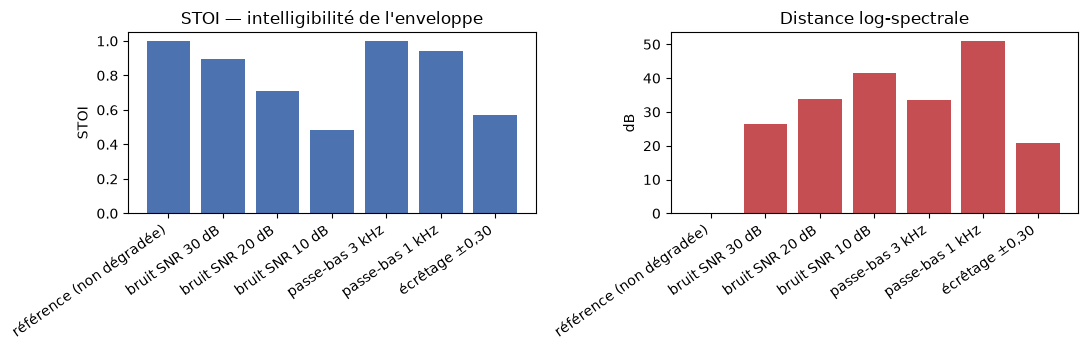

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt

labels = [name for name, _ in cases]
stoi_values = [stoi_value(reference, degraded) for _, degraded in cases]
lsd_values = [lsd(reference, degraded) for _, degraded in cases]

figure, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(labels, stoi_values, color="#4C72B0")
axes[0].set_title("STOI — intelligibilité de l'enveloppe")
axes[0].set_ylabel("STOI")
axes[0].set_ylim(0, 1.05)
axes[1].bar(labels, lsd_values, color="#C44E52")
axes[1].set_title("Distance log-spectrale")
axes[1].set_ylabel("dB")
for axe in axes:
    axe.tick_params(axis="x", rotation=35)
    for tick in axe.get_xticklabels():
        tick.set_ha("right")
figure.tight_layout()
plt.show()


### Lecture du résultat

Les deux histogrammes racontent la même histoire en négatif l'un de l'autre. À gauche, le STOI est **saturé** sur la plupart des cas : seul le bruit à 10 dB et l'écrêtage descendent nettement, et le passe-bas 3 kHz reste collé au plafond. À droite, la distance log-spectrale **distingue** chaque cas, y compris le passe-bas que le STOI ne voyait pas.

Un proxy ne se juge pas sur la valeur qu'il prend, mais sur **l'information qu'il garde**. Le STOI garde l'information « l'enveloppe temporelle est-elle intacte » ; il perd l'information « le timbre est-il fidèle ». La distance log-spectrale garde l'information spectrale, mais elle est aveugle à la phase et aux détails sous le seuil d'audition.

C'est l'argument du carnet, en une image : **un proxy classe, il ne note pas**. Il classe les dégradations qu'il a été calibré pour voir.


## 5. Quand le proxy suffit-il ?

Un proxy se substitue à l'oreille **dans la plage où il a été calé**, et seulement là. Le tableau ci-dessous résume la position de chaque mesure de la section 4.

| Mesure | Ce qu'elle capte | Ce qu'elle ne capte pas |
|---|---|---|
| SNR global | l'énergie d'erreur rapportée à une énergie de référence **fixe** | la nature de l'erreur : 7,8 % de l'énergie de référence sous écrêtage ±0,30, entre les bruits à 20 dB (1 %) et 10 dB (10 %) — sans ordre de qualité perceptive mesuré |
| SI-SDR | la fidélité de forme d'amplitude, à l'échelle près — elle voit la perte de bande passante (186,26 dB pour la référence, 0,95 dB sous passe-bas 3 kHz) | un gain global : l'invariance d'échelle la rend insensible au niveau |
| Distance log-spectrale (LSD) | l'écart de forme spectrale | la phase, et le dégradé sous le seuil d'audition |
| STOI | l'intelligibilité de l'enveloppe temporelle | la bande passante : 0,9988 sous passe-bas 3 kHz, où la LSD atteint 33,6 dB |

Le passe-bas 3 kHz est l'illustration centrale : **le STOI reste à 0,9988** alors que la LSD grimpe à 33,6 dB — un proxy peut être **aveugle** à la dégradation qu'il prétend mesurer. L'oreille, elle, entend un timbre mat.

### La limite assumée : PESQ n'est pas disponible ici

**PESQ** (ITU-T P.862) est le complément standard le plus courant pour comparer un signal dégradé à sa référence. Sa bibliothèque de référence n'est **pas installable sur ce poste** : la distribution est une archive source qui exige une compilation Cython/MSVC indisponible sous Windows — verdict `RECOVERABLE-MACHINE` (l'outil réel existe et fonctionne ailleurs ; il n'est ni contourné ni remplacé par une approximation présentée comme un PESQ).

Ce carnet ne fournit donc pas de PESQ. Il fournit la chaîne autour : la référence de laboratoire, les dégradations maîtrisées, les proxies réellement calculés, et le protocole qui décidera de l'oreille.


### Exercice 1 — Rejouer la séance avec une autre graine

Changez la graine du protocole et observez ce qui bouge : l'ordre de présentation change-t-il ? la fiche de notation suit-elle le nouvel ordre ? l'ancre reste-t-elle le même essai ?

Implémentez la manipulation dans la cellule suivante : appelez `mp.build_trial_list` avec une autre graine, comparez les deux ordres, et affichez la position de l'ancre dans les deux séances.


In [7]:
# Exercice 1 : rejouer la séance avec une autre graine.
# TODO etudiant : choisir une graine, puis appeler
#   mp.build_trial_list(items, seed=<votre graine>, anchor_ids=[items[0]["id"]])
# Indice : `items` et `rubric` sont déjà disponibles dans l'espace de noms.
trial_autre_graine = None  # TODO etudiant : remplacer par le résultat de l'appel

print("Exercice a completer : ordre de presentation avec la nouvelle graine")


Exercice a completer : ordre de presentation avec la nouvelle graine


### Exercice 2 — Mesurer l'effet du rejet P.808

Le rejet des auditeurs aberrants change le MOS et resserre l'intervalle de confiance. Mesurez cet effet : recalculez l'agrégat avec `reject_outliers=False`, comparez le MOS et l'intervalle avec ceux du rapport de la section 3, et dites lequel des deux résultats est le plus prudent à publier.

Implémentez le recalcul dans la cellule suivante : réutilisez `records` et `rubric`, appelez `mp.aggregate_mos` avec et sans rejet, et affichez les deux rapports.


In [8]:
# Exercice 2 : comparer l'agregat avec et sans rejet P.808.
# TODO etudiant : appeler
#   mp.aggregate_mos(records, rubric=rubric, reject_outliers=False)
# Indice : `records` contient deja la campagne fictive de la section 3.
report_sans_rejet = None  # TODO etudiant : remplacer par le rapport obtenu

print("Exercice a completer : rapport sans rejet P.808")


Exercice a completer : rapport sans rejet P.808


### Exercice 3 — Mesurer une dégradation supplémentaire

Les trois familles de dégradation de la section 4 (bruit additif, bande passante, écrêtage) n'épuisent pas le catalogue. Ajoutez-en une — quantification 8 bits, par exemple — et mesurez les quatre proxies.

Implémentez la mesure dans la cellule suivante : construisez la version quantifiée du signal de référence, appelez les quatre fonctions de mesure, et affichez le tableau.

Interprétez ensuite : le proxy qui réagit le plus est-il celui qui décrit le mieux la dégradation ? C'est la bonne question à se poser devant chaque proxy.


In [9]:
# Exercice 3 : mesurer une degradation supplementaire (quantification 8 bits).
# TODO etudiant : quantifier la reference (np.round(reference * 128) / 128),
# puis mesurer snr_db, si_sdr, lsd et stoi_value sur le resultat.
# Indice : `reference`, `snr_db`, `si_sdr`, `lsd` et `stoi_value` sont definis plus haut.
degradee_quantifiee = None  # TODO etudiant : remplacer par le signal quantifie

print("Exercice a completer : proxies de la degradation par quantification 8 bits")


Exercice a completer : proxies de la degradation par quantification 8 bits


## Conclusion

Ce que la séance apporte : un **organe** (`scripts/tts_verification/mos_protocol.py`) qui lit la rubrique du `04-7`, produit un protocole rejouable et agrège des notes en MOS avec intervalle de confiance et rejet P.808 ; un carnet qui l'importe sans le recopier et le met en situation sur des **notes explicitement fictives** ; et une démonstration mesurée que **les proxies classent, ils ne notent pas**.

Ce que la séance ne dit pas : rien sur la qualité d'un moteur de TTS. Aucun MOS humain n'a été recueilli ici, et la grille du `04-7` reste vide — c'est l'auditeur qui la remplira.

### Références

- ITU-T P.800 (1996), *Methods for subjective determination of transmission quality*, UIT.
- ITU-R P.808 (2015), *Reference test methods for the perceptual assessment of audio quality*, UIT.
- ITU-T P.862 (2001), *Perceptual evaluation of speech quality (PESQ)*, UIT — non calculé ici (voir la limite de la section 5).
- Copie déposée d'ITU-T P.800.1 (07/2006), *Mean Opinion Score (MOS) terminology* : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Audio\2006 - ITU - Mean Opinion Score (MOS) terminology - ITU-T P.800.1.pdf` (source et état du dépôt dans le fichier `...- source.md` du même dossier). Les textes intégraux de P.800, P.808 et P.862 ne sont pas archivés : le portail ITU refuse le téléchargement automatisé depuis ce poste, et la demande de dépôt est inscrite au registre des questions de la lane.
- Métriques `torchmetrics` (SI-SDR, STOI) et `pystoi` : calculées par les bibliothèques réelles, aucune réimplémentation locale.
